[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/23_retina_ln_mosaic.ipynb)

# Retina: LN models of a W3 and a tOFFalpha cell, and the Fisher information of their mosaics

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Fit a linear–nonlinear–Poisson (LN) model to the recorded spike counts of the two reference cells of notebooks 12 to 21 (W3 176-exp7, tOFFalpha 17-exp5), copy each on a hexagonal lattice into a mosaic, and plot the Fisher information J(x) of each cell of the mosaic and its total per pixel, diag J(x), on the frog (the example image of notebooks 7, 8 and 11).

* **Requirements**: the recordings (Hugging Face dataset `steevelaquitaine/lorenzi-retina-recordings`, private), TinyImageNet (the frog), and `multigeom` from the `g-per-scale` branch. A CPU is enough.

* **Time**: about a minute.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.datasets": {"download_tinyimagenet": [], "load_lorenzi_cell": []},
        "multigeom.encoders.ln": {
            "LNCell": [],
            "LNMosaic": [],
            "count_noise": [],
            "fit_ln_cell": ["steps"],
        },
        "multigeom.encoders.retina": {"load_stimulus_frames": []},
        "multigeom.geometry": {"compute_fisher_per_cell": ["noise"]},
        "multigeom.plotting": {"plot_mosaic_fisher": []},
        "multigeom.utils": {"load_intermediate": [], "save_intermediate": []},
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

    # open-retina-multigeom, with Baptiste Lorenzi's retina models, if missing: a
    # private repository (GitHub access through git's credentials, or a token in the
    # environment variable GH_TOKEN), forced over a public openretina, which lacks them
    import importlib.util

    try:
        retina = importlib.util.find_spec("openretina.insilico.information_geometry")
    except ModuleNotFoundError:
        retina = None
    if retina is None:
        TOKEN = os.environ.get("GH_TOKEN", "")
        RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
        URL = f"https://{TOKEN}@{RETINA}" if TOKEN else f"https://{RETINA}"
        %pip install -q --no-deps --force-reinstall "git+{URL}"
        DEPENDENCIES = (
            "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
        )
        %pip install -q {DEPENDENCIES} moviepy
        print("installed open-retina-multigeom: restart the kernel")

CPU times: user 3.5 s, sys: 169 ms, total: 3.67 s
Wall time: 1.53 s


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the cells, the recordings, the fit, the mosaics, the image, and where the results and figures go.

<details><summary>Details</summary>

* **The LN model** (`multigeom.encoders.ln`): λ(x) = r_max σ(⟨w, x − grey⟩ + b), the expected spike count during the natural image (bins 16 to 31, 400 ms), with Poisson counts; w is a difference of Gaussians (a centre and an opposite-sign surround). It generalises the LN-sigmoid encoder of `proj_zsmultigeom` (`encoders/lnp.py`) with a surround and fitted parameters.
* **The fit** (`fit_ln_cell`): Poisson likelihood of the counts of the training clips (one trial each, all after a grey adapting image), started at the peak of the spike-triggered average.
* **The mosaic** (`LNMosaic`): the fitted cell copied on a hexagonal lattice 200 µm apart on 120 x 120 images at the cell's µm per pixel, as the mosaics of the deep Lorenzi models (notebooks 12 to 21).
* **Its Fisher information** (`compute_fisher_per_cell` with `count_noise`): exact, rank one per cell, $g_n g_n^\top$ with $g_n = \lambda_n' w_n / \sqrt{{\lambda_n}}$.

</details>

In [2]:
%%time

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/ and
# assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.datasets import download_tinyimagenet, load_lorenzi_cell
from multigeom.encoders.ln import LNCell, LNMosaic, count_noise, fit_ln_cell
from multigeom.encoders.retina import load_stimulus_frames
from multigeom.geometry import compute_fisher_per_cell
from multigeom.plotting import plot_mosaic_fisher
from multigeom.utils import load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the cells: the reference cells of notebooks 12 to 21
    "cells": {"W3": "176-exp7", "tOFFalpha": "17-exp5"},
    # the recordings, downloaded from the Hugging Face dataset if not there
    "recordings": "steevelaquitaine/lorenzi-retina-recordings",
    "data_dir": "data/lorenzi_adaptation/data",
    # the fit: the bins of the response (the natural image), the steps of Adam, and
    # the share of the training clips held out to check the fit
    "response_bins": [16, 32],
    "steps": 3000,
    "held_out": 0.2,
    # the mosaic: the image size and the lattice spacing (as notebooks 12 to 21)
    "canvas": 120,
    "spacing_um": 200.0,
    # the image: the frog of notebooks 7, 8 and 11 (a TinyImageNet training image),
    # prepared as the recorded stimuli (grayscale, 120 x 120, standardised)
    "images": {
        "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG"
    },
    # the figures: the strongest cells kept and drawn, each as the 32 x 32 pixels
    # around its peak, and the title of the rows
    "n_fisher_cells": 24,
    "fisher_crop": 32,
    "fisher_title": "J(x) per cells of the mosaic",
    # where the results are stored (True: recompute and overwrite them), where the
    # figures are saved, their resolution in the file and on screen, and the images
    # whose figures stay in the notebook
    "intermediate_dir": "data/02_intermediate/23_retina_ln_mosaic",
    "recompute": False,
    "figure_dir": "assets/figures/retina/ln_mosaic",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["frog"],
}

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials
CPU times: user 39.4 ms, sys: 4.97 ms, total: 44.3 ms
Wall time: 43.8 ms


## 2. Download the recordings and the datasets

The recordings from the private Hugging Face dataset `steevelaquitaine/lorenzi-retina-recordings` (5.3 GB, the first time only; a Hugging Face login with access to it), and TinyImageNet for the frog.

In [3]:
%%time

# the recordings, if they are not already here, and TinyImageNet
data_dir = Path(PARAMS["data_dir"])
if not any(data_dir.glob("*.npz")):
    snapshot_download(
        repo_id=PARAMS["recordings"], repo_type="dataset", local_dir=data_dir.parent
    )
download_tinyimagenet()

# the stored results of this notebook, from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
if not PARAMS["recompute"]:
    try:
        snapshot_download(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=["23_retina_ln_mosaic/*"],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

Fetching 0 files: 0it [00:00, ?it/s]

CPU times: user 15.4 ms, sys: 1.96 ms, total: 17.3 ms
Wall time: 150 ms


## 3. Fit an LN model to each cell

For each cell: the spike count during the natural image of each training clip, the LN model fitted to 80% of them, and two checks: the correlation of its predictions with the counts of the 20% held out (single trials), and with the mean counts over the 30 repeats of the test clips adapted to grey (10 clips for exp5, 5 for exp7). The fits are stored in `data/02_intermediate/23_retina_ln_mosaic/fits.pt`.

In [4]:
%%time

fits_file = Path(PARAMS["intermediate_dir"]) / "fits.pt"
if fits_file.exists() and not PARAMS["recompute"]:
    fits = load_intermediate(fits_file)
else:
    fits = {}
    first, last = PARAMS["response_bins"]
    for cell_type, name in PARAMS["cells"].items():
        # the natural image and spike count of each training clip
        rec = load_lorenzi_cell(data_dir, name)
        stimuli = torch.tensor(rec.frames[rec.train_natural])
        counts = torch.tensor(rec.train_counts[:, first:last].sum(axis=1))
        split = int((1 - PARAMS["held_out"]) * len(counts))

        # the fit, then its two checks
        cell, losses = fit_ln_cell(
            stimuli[:split], counts[:split], rec.grey, steps=PARAMS["steps"]
        )
        grey = rec.test_adapt == 1
        test = torch.tensor(rec.frames[rec.test_natural[grey]])
        observed = rec.test_counts[grey][:, :, first:last].sum(axis=2).mean(axis=1)
        with torch.no_grad():
            held_out = np.corrcoef(cell(stimuli[split:]), counts[split:])[0, 1]
            tested = np.corrcoef(cell(test), observed)[0, 1]
        fits[cell_type] = {
            "cell": name,
            "state": cell.state_dict(),
            "size": cell.size,
            "grey": cell.grey,
            "microns_per_px": rec.metadata["microns_per_px"],
            "parameters": cell.describe(),
            "held_out_r": held_out,
            "test_r": tested,
            "n_test_clips": int(grey.sum()),
            "losses": losses,
        }
    save_intermediate(fits, fits_file)

for cell_type, fit in fits.items():
    print(f"{cell_type} {fit['cell']}: {fit['parameters']}")
    print(
        f"  held-out training clips r = {fit['held_out_r']:.2f}, test clips adapted to"
        f" grey ({fit['n_test_clips']}) r = {fit['test_r']:.2f}"
    )

W3 176-exp7: {'center': [20.03, 19.26], 'sigma_center_px': 3.2, 'sigma_surround_px': 8.83, 'surround_weight': 0.995, 'polarity': 'OFF', 'max_count': 1093.26}
  held-out training clips r = 0.51, test clips adapted to grey (5) r = 0.96
tOFFalpha 17-exp5: {'center': [15.44, 15.16], 'sigma_center_px': 2.17, 'sigma_surround_px': 10.57, 'surround_weight': 0.313, 'polarity': 'OFF', 'max_count': 8.28}
  held-out training clips r = 0.63, test clips adapted to grey (10) r = 0.99
CPU times: user 2.27 ms, sys: 0 ns, total: 2.27 ms
Wall time: 1.93 ms


## 4. The Fisher information of the mosaics

Each fitted cell copied on a hexagonal lattice 200 µm apart on 120 x 120 images, and, for the frog, the Fisher information of each cell of the mosaic (the 24 strongest kept) and its total per pixel, diag J(x). Stored in `data/02_intermediate/23_retina_ln_mosaic/fisher.pt`.

In [5]:
%%time

# the images, in the units of the recorded stimuli
names = list(PARAMS["images"])
images = load_stimulus_frames(list(PARAMS["images"].values()), PARAMS["canvas"])


def get_strongest(fisher: dict, n_cells: int) -> dict:
    """The Fisher information of the `n_cells` strongest cells, with the total over
    all the cells per pixel ("diag")."""
    order = fisher["cell_values"].argsort()[::-1][:n_cells]
    return {
        "cells": fisher["cells"][order].astype("float32"),
        "cell_values": fisher["cell_values"][order],
        "diag": (fisher["cells"] ** 2).sum(axis=0),
    }


fisher_file = Path(PARAMS["intermediate_dir"]) / "fisher.pt"
if fisher_file.exists() and not PARAMS["recompute"]:
    fisher = load_intermediate(fisher_file)
else:
    fisher = {}
    for cell_type, fit in fits.items():
        # the fitted cell, then its mosaic
        cell = LNCell(fit["size"], fit["grey"])
        cell.load_state_dict(fit["state"])
        mosaic = LNMosaic(
            cell, PARAMS["canvas"], fit["microns_per_px"], PARAMS["spacing_um"]
        )
        print(f"{cell_type} mosaic: {mosaic.n_neurons} cells")

        # the Fisher information per cell, with Poisson counts, of each image
        noise = count_noise(mosaic.n_neurons)
        fisher[cell_type] = {
            name: get_strongest(
                compute_fisher_per_cell(
                    image[None], mosaic, 1.0, torch.device("cpu"), noise=noise
                ),
                PARAMS["n_fisher_cells"],
            )
            for name, image in zip(names, images)
        }
    save_intermediate(fisher, fisher_file)

CPU times: user 11.9 ms, sys: 3.97 ms, total: 15.8 ms
Wall time: 15.3 ms


## 5. Plot J(x) per cell of the mosaic and diag J(x)

The figure is saved to `assets/figures/retina/ln_mosaic/ln_mosaic_fisher_frog.png`: the frog, and for each mosaic the Fisher information of its 24 strongest cells (each as the 32 x 32 pixels around its peak, strongest first) and its total per pixel, diag J(x), on the whole image.

1 figures saved in assets/figures/retina/ln_mosaic
CPU times: user 428 ms, sys: 6.06 ms, total: 434 ms
Wall time: 434 ms


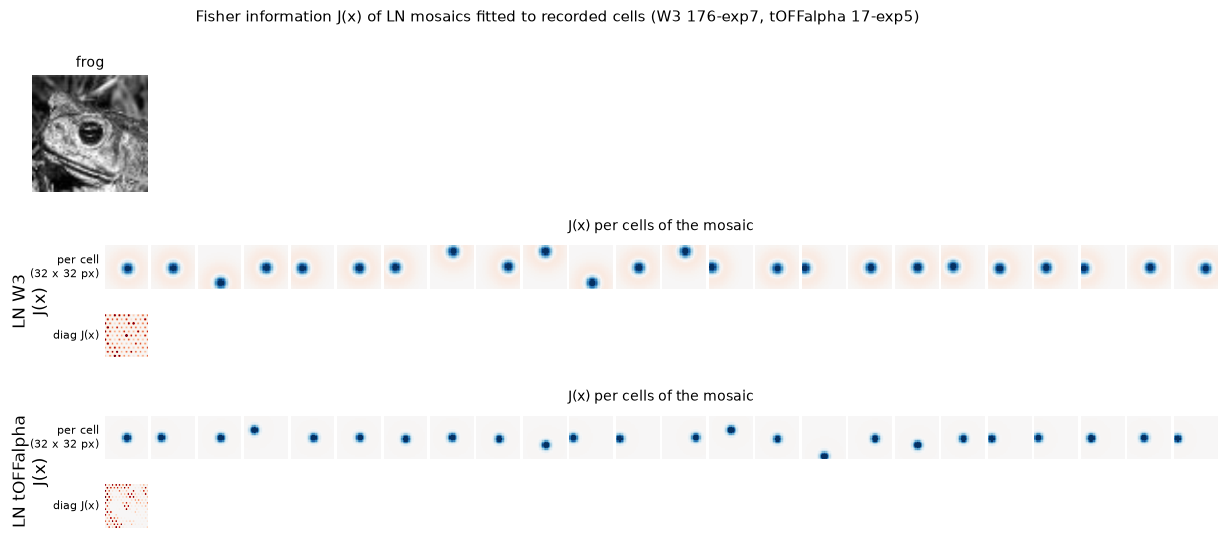

In [6]:
%%time

figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
cells = ", ".join(f"{t} {fit['cell']}" for t, fit in fits.items())
suptitle = f"Fisher information J(x) of LN mosaics fitted to recorded cells ({cells})"
for i, name in enumerate(names):
    records = {f"LN {cell_type}": fisher[cell_type][name] for cell_type in fisher}
    fig, _ = plot_mosaic_fisher(images[i], records, PARAMS, name, suptitle)
    fig.savefig(
        figure_dir / f"ln_mosaic_fisher_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)
print(len(names), "figures saved in", figure_dir)

## 6. Conclusion

* **The LN fits.** W3 176-exp7: an OFF centre (width 3.2 pixels) with a nearly balanced surround (8.8 pixels, weight 0.99); tOFFalpha 17-exp5: an OFF centre (2.2 pixels) with a weak surround (10.6 pixels, weight 0.31). Their predictions correlate with the counts of held-out training clips at r = 0.51 and 0.63 (single trials), and with the mean counts of the test clips adapted to grey at r = 0.96 (5 clips) and 0.99 (10 clips).
* **The Fisher information of the LN mosaics** (105 and 188 cells) is exact and simple: each cell's pattern is its own receptive field, scaled by how steeply its rate changes at the image. diag J(x) shows where on the frog the mosaic's cells sit in the steep part of their sigmoid.
* **Mosaic edges.** The lattice fills the whole image, so cells near its border lose part of their surround; with W3's balanced surround, they then respond to the image's overall brightness. The mosaics of the deep Lorenzi models have fewer cells (80 and 150), probably because they keep a margin.
* **Next steps.** Compare with the Fisher rows of the deep Lorenzi mosaics on the frog.